# Atomic clocks: Ramsey fringes, relativity, IEEE 754, loops vs vectorized, and a random forest
### SymPy derivations · how much time each clock loses · why floating point loses time · ML on clock noise

**In plain words.** An atomic clock steers an oscillator so it stays locked to an atom's
transition frequency. For cesium that is exactly 9,192,631,770 Hz, which defines the SI second.
This notebook covers:
1. **Physics:** Ramsey interrogation and the quantum limit on clock stability, derived in SymPy.
2. **Time lost:**
   - how far each kind of clock drifts in a day without GPS;
   - why GPS clocks need Einstein's corrections;
   - how computers themselves lose time through floating-point arithmetic (IEEE 754), including
     the 1991 Patriot clock bug.
3. **Computing:** the Allan deviation, the standard clock-stability statistic, written as a loop
   and as vectorized NumPy, then timed. A C version of the time-accumulation comparison.
4. **ML:** a decision tree and a random forest learn to recognize five kinds of clock noise.

Clock grades and cost tiers are order-of-magnitude classes, not product specifications. Every
figure uses the Okabe–Ito colorblind-safe palette, distinguishes curves by line style as well as
color, and has a printed text description.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import sympy as sp
import sys, pathlib, time, os, shutil, subprocess
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from dgs import atomic_clock as a
sp.init_printing()
OI = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OI)

## 1. Ramsey interrogation

Two $\pi/2$ pulses separated by a free-evolution time $T$: the first creates a superposition, the
superposition accumulates phase $\Delta T$ relative to the oscillator, and the second converts that
phase into a population. This is the same interferometer as `quantum_gyroscope.ipynb`, run in time
instead of space. SymPy multiplies the three 2×2 matrices:

In [2]:
P = a.ramsey_symbolic()
display(sp.Eq(sp.Symbol("P_excited"), P), sp.Eq(sp.Symbol("FWHM (Hz)"), a.ramsey_fwhm_symbolic()))

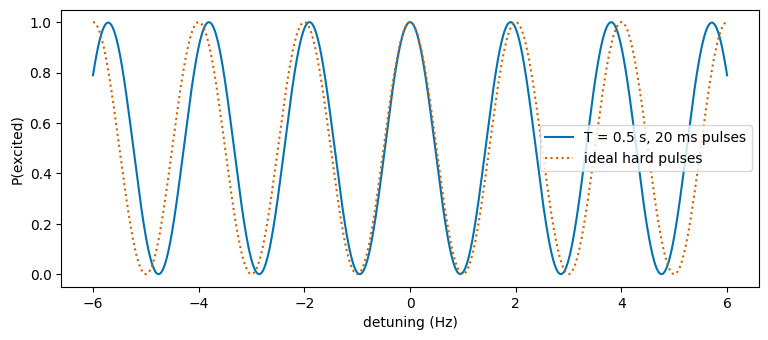

Figure description: Ramsey fringes, cosine oscillations with 1 Hz spacing for T = 0.5 s. With finite pulses (solid) the fringes sit under a slowly decaying envelope; the ideal hard-pulse model (dotted) has full contrast everywhere.


In [3]:
df = np.linspace(-6, 6, 2001)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(df, a.ramsey_fringe(df, 0.5, pulse_time=0.02), "-", label="T = 0.5 s, 20 ms pulses")
ax.plot(df, a.ramsey_fringe(df, 0.5), ":", label="ideal hard pulses")
ax.set_xlabel("detuning (Hz)"); ax.set_ylabel("P(excited)"); ax.legend(); plt.show()
print("Figure description: Ramsey fringes, cosine oscillations with 1 Hz spacing for T = 0.5 s. With finite pulses (solid) "
      "the fringes sit under a slowly decaying envelope; the ideal hard-pulse model (dotted) has full contrast everywhere.")

The central fringe is $1/(2T)$ wide: 1 Hz for $T=0.5$ s, on a 9.19 GHz carrier. Longer free
time gives narrower fringes and a better clock. That's why cesium **fountains** toss atoms up and
let them fall back, for $T$ near a second.

## 2. The quantum limit on stability

Each cycle measures $N$ atoms. Projection noise gives a phase uncertainty of $1/\sqrt N$, which
turns into a fractional-frequency uncertainty. Averaging over $\tau/T_c$ cycles gives the
**Allan deviation**:

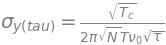

cesium fountain (T = 0.5 s, 1e6 atoms, 1 s cycle): sigma_y(1 s) = 3.46e-14, sigma_y(1 day) = 1.18e-16
optical Sr  (T = 0.5 s, 1e4 atoms, 1 s cycle): sigma_y(1 s) = 7.42e-18


In [4]:
display(sp.Eq(sp.Symbol("sigma_y(tau)"), a.qpn_allan_symbolic()))
print(f"cesium fountain (T = 0.5 s, 1e6 atoms, 1 s cycle): sigma_y(1 s) = {a.qpn_allan(1, a.NU_CS, 0.5, 1e6, 1.0):.2e}, "
      f"sigma_y(1 day) = {a.qpn_allan(a.DAY, a.NU_CS, 0.5, 1e6, 1.0):.2e}")
print(f"optical Sr  (T = 0.5 s, 1e4 atoms, 1 s cycle): sigma_y(1 s) = {a.qpn_allan(1, a.NU_SR, 0.5, 1e4, 1.0):.2e}")

Optical clocks win by about $10^5$ in carrier frequency: they "tick" at ~430 THz instead of
9 GHz.

## 3. How much time each clock loses without GPS

A leftover fractional frequency offset $y$ makes the time error grow as $x(t)=y\,t$. After one day:

In [5]:
for k, (err, cost) in a.holdover_table().items():
    y = a.CLOCK_GRADES[k][0]
    print(f"{k:28s} y ~ {y:.0e}   error after 1 day ~ {err:9.2e} s   cost tier: {cost}")
print(f"\nlight travels {a.C*1e-9:.2f} m in 1 ns: 1 us of clock error = {a.C*1e-6:.0f} m of GPS-style ranging error")

quartz TCXO                  y ~ 1e-07   error after 1 day ~  8.64e-03 s   cost tier: dollars to tens of dollars
oven quartz (OCXO)           y ~ 1e-09   error after 1 day ~  8.64e-05 s   cost tier: hundreds of dollars
chip-scale atomic (CSAC)     y ~ 1e-11   error after 1 day ~  8.64e-07 s   cost tier: thousands of dollars
rubidium                     y ~ 1e-11   error after 1 day ~  8.64e-07 s   cost tier: thousands of dollars
cesium beam                  y ~ 1e-13   error after 1 day ~  8.64e-09 s   cost tier: tens of thousands of dollars
hydrogen maser               y ~ 1e-15   error after 1 day ~  8.64e-11 s   cost tier: hundreds of thousands of dollars
optical lattice (lab)        y ~ 1e-18   error after 1 day ~  8.64e-14 s   cost tier: research lab, millions in infrastructure

light travels 0.30 m in 1 ns: 1 us of clock error = 300 m of GPS-style ranging error


This is the timing half of GPS-free navigation (`gps_denied_navigation.ipynb`). A quartz
clock's error after a day corresponds to thousands of kilometers of ranging error. A cesium clock's
is a few meters.

## 4. Relativity: why GPS clocks are set to run slow

A satellite clock sits higher in Earth's gravity (it runs **faster**) and moves fast (it runs
**slower**). SymPy derives both terms for a circular orbit:

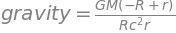

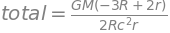

GPS orbit: gravity +45.72 us/day, velocity -7.21 us/day, net +38.51 us/day  ->  ~11.5 km/day of ranging error if ignored
raise a clock by 1 m: fractional shift 1.09e-16  (optical clocks resolve this -- they are height sensors)


In [6]:
grav, vel, tot = a.gps_relativity_symbolic()
display(sp.Eq(sp.Symbol("gravity"), grav), sp.Eq(sp.Symbol("velocity"), vel), sp.Eq(sp.Symbol("total"), tot))
g, v, t_ = a.gps_relativity_us_per_day()
print(f"GPS orbit: gravity {g:+.2f} us/day, velocity {v:+.2f} us/day, net {t_:+.2f} us/day  ->  ~{t_*1e-6*a.C/1e3:.1f} km/day of ranging error if ignored")
print(f"raise a clock by 1 m: fractional shift {a.height_shift(1.0):.2e}  (optical clocks resolve this -- they are height sensors)")

## 5. IEEE 754: computers lose time too

A double (IEEE 754 binary64) holds about 16 significant digits. Problems:
* The Sr optical frequency, about $4.3\times10^{14}$ Hz, can only be stored to the nearest
  0.0625 Hz, a fractional resolution of about $1.5\times10^{-16}$. That's coarser than the
  $10^{-18}$ the clock measures. Real software stores **offsets** from a nominal value instead.
* Summing a 0.1 s tick accumulates rounding error. 0.1 has no exact binary representation.
* In 1991 a Patriot missile battery's clock stored 0.1 s truncated in a 24-bit fixed-point
  register. After about 100 hours of operation it was off by about a third of a second, and its
  tracking failed (U.S. GAO report IMTEC-92-26).

In [7]:
print(f"double resolution at 1e9 s (31 years of seconds): {a.float_resolution(1e9):.3e} s")
print(f"double resolution at nu_Sr: {a.float_resolution(a.NU_SR)} Hz  -> fractional {a.float_resolution(a.NU_SR)/a.NU_SR:.2e}")
print(f"float32 resolution at 360000 s: {a.float_resolution(360000, np.float32)} s\n")
for name, dt in (("float32", np.float32), ("float64", np.float64)):
    s = a.accumulate_time_fast(dtype=dt)
    print(f"sum 0.1 s x 3,600,000 in {name}: {s:.6f} s  (error {s-360000:+.6e} s)")
per, tot = a.patriot_chop_error()
print(f"24-bit fixed point (0.1 chopped to 23 fractional bits): {per:.4e} s per tick -> {tot:.4f} s after 100 h")
print(f"SymPy exact rational sum: {a.exact_sum_symbolic()} s")

double resolution at 1e9 s (31 years of seconds): 1.192e-07 s
double resolution at nu_Sr: 0.0625 Hz  -> fractional 1.46e-16
float32 resolution at 360000 s: 0.03125 s

sum 0.1 s x 3,600,000 in float32: 347024.781250 s  (error -1.297522e+04 s)
sum 0.1 s x 3,600,000 in float64: 359999.999988 s  (error -1.201301e-05 s)
24-bit fixed point (0.1 chopped to 23 fractional bits): 9.5367e-08 s per tick -> 0.3433 s after 100 h
SymPy exact rational sum: 360000 s


Float32 loses more than **3.6 hours** out of 100. Once the running total is large, each 0.1 s
step gets rounded to the nearest representable value, a few hundredths of a second at that
magnitude. The same experiment in C, with a `uint64_t` nanosecond counter (the standard fix, used
by operating-system clocks):

In [8]:
gcc = shutil.which("gcc") or (r"C:\msys64\mingw64\bin\gcc.exe" if os.path.exists(r"C:\msys64\mingw64\bin\gcc.exe") else None)
if gcc:
    env = dict(os.environ, PATH=str(pathlib.Path(gcc).parent) + os.pathsep + os.environ.get("PATH", ""))
    exe = pathlib.Path(os.environ.get("TEMP", "/tmp")) / "time_accum.exe"
    subprocess.run([gcc, "-std=c99", "-O2", "-Wall", "-Wextra", str(pathlib.Path.cwd().parent / "learn" / "atomic_clock" / "time_accum.c"), "-o", str(exe)], check=True, env=env)
    print(subprocess.run([str(exe)], capture_output=True, text=True, env=env).stdout)
else:
    print("gcc not found -- see learn/atomic_clock/time_accum.c")

float    total=347024.781250 s  error=-12975.218750 s
double   total=359999.999987987 s  error=-1.201e-05 s
uint64ns total=360000.000000000 s  error=+0.000e+00 s
fixed23  total=359999.656677 s  error=-0.343323 s



Integers don't round. Count ticks in integer nanoseconds and convert to seconds only for
display. The C output matches the Python results digit for digit.

## 6. The Allan deviation: loops vs vectorized

The Allan variance is half the mean square of the **second difference** of the time error,
divided by $\tau^2$. A constant frequency offset cancels exactly:

In [9]:
sp.Eq(sp.Symbol("x(t+2tau) - 2x(t+tau) + x(t)  for  x = x0 + y t"), a.adev_symbolic_second_difference())

In [10]:
y = a.powerlaw_frequency_noise(200_000, 1.0, 0, rng=0); x = a.phase_from_frequency(y, 1.0)
m = 10
t0 = time.perf_counter(); s_loop = a.adev_loop(x, 1.0, m); t1 = time.perf_counter()
s_vec = a.adev(x, 1.0, m); t2 = time.perf_counter()
print(f"loop:       {s_loop:.12f}   {1e3*(t1-t0):8.2f} ms")
print(f"vectorized: {s_vec:.12f}   {1e3*(t2-t1):8.2f} ms   -> {(t1-t0)/(t2-t1):.0f}x faster, same answer")

loop:       0.315854730162      95.09 ms
vectorized: 0.315854730162       2.00 ms   -> 48x faster, same answer


The loop and the slicing expression compute the same sum; NumPy just runs it in compiled C
over whole arrays. The modified Allan deviation goes further and uses **cumulative sums**, so each
$m$-sample average costs O(1) instead of O(m).

## 7. Five kinds of clock noise, and their fingerprints

Clock noise comes in power laws $S_y(f)\propto f^\beta$. Each one leaves a characteristic slope in
ADEV and MDEV versus averaging time:

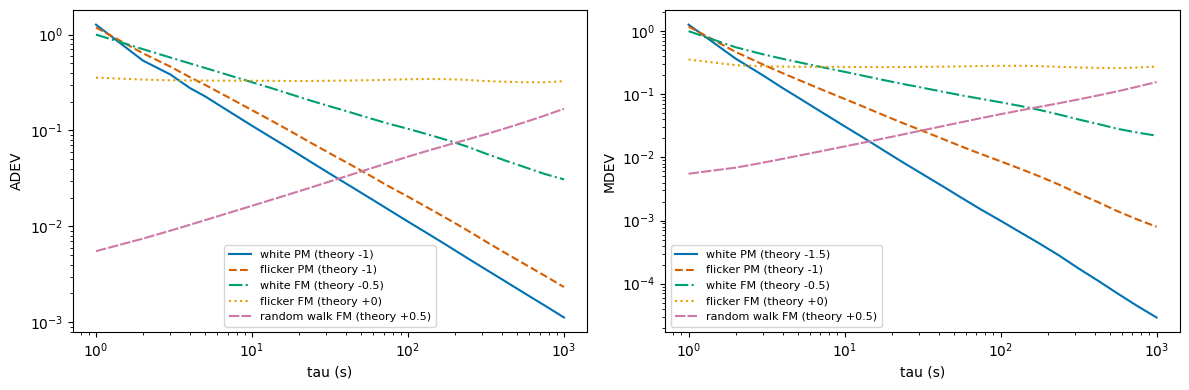

Figure description: log-log ADEV (left) and MDEV (right) versus averaging time for five noise types, each with its own line style. On the left, white PM and flicker PM both fall steeply with nearly the same slope; on the right, MDEV separates them, with white PM falling faster than flicker PM.


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ms = np.unique(np.logspace(0, 3, 25).astype(int)); ls_ = ["-", "--", "-.", ":", (0, (5, 1))]
theory = {"white PM": (-1, -1.5), "flicker PM": (-1, -1), "white FM": (-0.5, -0.5), "flicker FM": (0, 0), "random walk FM": (0.5, 0.5)}
for (k, b), ls in zip(a.NOISE_BETA.items(), ls_):
    xx = a.phase_from_frequency(a.powerlaw_frequency_noise(2**16, 1.0, b, rng=3), 1.0)
    ax[0].loglog(ms, [a.adev(xx, 1.0, m) for m in ms], ls=ls, label=f"{k} (theory {theory[k][0]:+g})")
    ax[1].loglog(ms, [a.mdev(xx, 1.0, m) for m in ms], ls=ls, label=f"{k} (theory {theory[k][1]:+g})")
for axx, t in zip(ax, ("ADEV", "MDEV")):
    axx.set_xlabel("tau (s)"); axx.set_ylabel(t); axx.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Figure description: log-log ADEV (left) and MDEV (right) versus averaging time for five noise types, each with "
      "its own line style. On the left, white PM and flicker PM both fall steeply with nearly the same slope; on the "
      "right, MDEV separates them, with white PM falling faster than flicker PM.")

Textbook theory says **white PM and flicker PM have the same ADEV slope** ($\tau^{-1}$),
which is why the modified Allan deviation was invented. Its slopes are $-3/2$ and $-1$.

## 8. Decision tree and random forest

Features: the log-log ADEV and MDEV slopes between successive averaging times (12 numbers per
record). Labels: the five noise types. 300 synthetic records, with a 70/30 split:

ADEV + MDEV slopes   decision tree 1.000   random forest 1.000


ADEV slopes only     decision tree 0.989   random forest 1.000


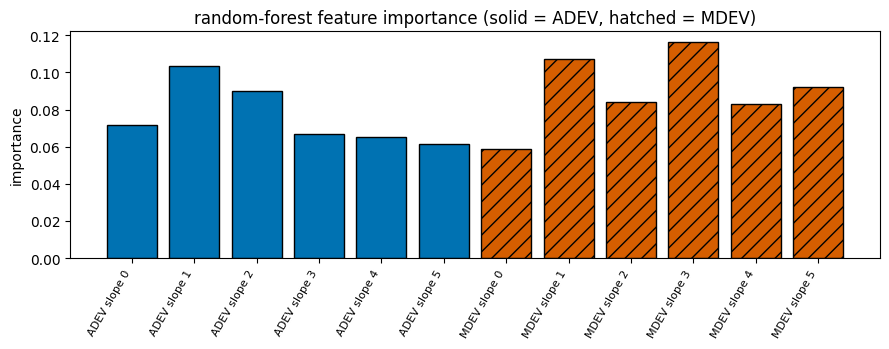

|--- ADEV slope 1 <= -0.88
|   |--- class: white PM
|--- ADEV slope 1 >  -0.88
|   |--- MDEV slope 2 <= -0.29
|   |   |--- MDEV slope 4 <= -0.71
|   |   |   |--- class: flicker PM
|   |   |--- MDEV slope 4 >  -0.71
|   |   |   |--- class: white FM
|   |--- MDEV slope 2 >  -0.29
|   |   |--- ADEV slope 0 <= 0.19
|   |   |   |--- class: flicker FM
|   |   |--- ADEV slope 0 >  0.19
|   |   |   |--- class: random walk FM

Figure description: bar chart of 12 feature importances; solid blue bars are ADEV slopes and hatched vermillion bars are MDEV slopes. The printed tree shows the threshold rules the decision tree learned.


In [12]:
X, y = a.make_noise_dataset(n_per_class=60, n=4096, rng=0)
for name, only in (("ADEV + MDEV slopes", False), ("ADEV slopes only", True)):
    r = a.train_classifiers(X, y, adev_only=only)
    print(f"{name:20s} decision tree {r['tree_acc']:.3f}   random forest {r['forest_acc']:.3f}")
r = a.train_classifiers(X, y)
names = [f"ADEV slope {i}" for i in range(6)] + [f"MDEV slope {i}" for i in range(6)]
imp = r["forest"].feature_importances_
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(12), imp, color=[OI[0]]*6 + [OI[1]]*6, edgecolor="black", hatch="")
for i in range(6, 12): ax.patches[i].set_hatch("//")
ax.set_xticks(range(12)); ax.set_xticklabels(names, rotation=60, ha="right", fontsize=8); ax.set_ylabel("importance")
ax.set_title("random-forest feature importance (solid = ADEV, hatched = MDEV)"); plt.tight_layout(); plt.show()
from sklearn.tree import export_text
print(export_text(r["tree"], feature_names=names, max_depth=3))
print("Figure description: bar chart of 12 feature importances; solid blue bars are ADEV slopes and hatched vermillion "
      "bars are MDEV slopes. The printed tree shows the threshold rules the decision tree learned.")

**An honest result.** Even with ADEV slopes alone, the classifiers separate white PM from
flicker PM. The "same slope" statement is about the leading power law: flicker PM's ADEV carries an
extra logarithmic factor that bends its measured slope to about −0.9 instead of −1.0, and the tree
learns that small difference. MDEV makes the separation large (about −1.5 vs −1.1), so it's the
robust choice when data is noisy or short.

**Limits of this example:**
* Real clocks show **mixtures** of noise types, with crossovers between them. A practical
  classifier would label each τ-region, not the whole record.
* Synthetic training data can't stand in for validation on measured data.

## 9. Summary

| topic | result |
|---|---|
| Ramsey | $P=\tfrac12(1+\cos\Delta T)$, FWHM $=1/2T$ |
| quantum limit | $\sigma_y=\sqrt{T_c/\tau}/(2\pi\nu_0T\sqrt N)$ |
| holdover (1 day) | quartz ~ ms, CSAC ~ µs, cesium ~ ns, optical ~ 0.1 ps |
| GPS relativity | +45.7 (gravity) − 7.2 (speed) = **+38.5 µs/day** |
| IEEE 754 | float32 loses 3.6 h of 100 h; double ~12 µs; `uint64_t` ns exact; Patriot 0.343 s |
| loops vs vectorized | same Allan deviation, about 40–70× faster vectorized (varies run to run) |
| ML | tree and forest near 100%; MDEV makes PM-type separation robust |

**Connections to the rest of the repo:**
* The Ramsey sequence is `quantum_gyroscope`'s interferometer run in time instead of space.
* Locking the oscillator to the atoms is the `lockin_amplifier` tracking loop.
* The IEEE 754 lesson applies to every long-running instrument, including the RogueGuard firmware.

*Synthetic data; civilian education.*